# Paper reproduction: radiopyo before and after the refactoring

The paper grid of `tonneau_2025_pmb.ipynb` (19 dose rates × 19 pO$_2$ × 3 doses, single pulse, pure water, shipped GF(DR) fit) was run twice:

- **before**: commit `2261b92`, the code as it was before the refactoring sessions started on 2026-11-09 (the golden data of `tests/golden/` were first recorded on it). Written by `record_pre_refactor.py` into `data/paper_tonneau_2025_2261b92.npz`, from a separate checkout and interpreter (that commit does not run under pandas 3), with the same numpy 2.4.6 and scipy 1.17.1;
- **after**: the current code, `tests/golden/data/paper_tonneau_2025.npz`.

Both use the same `paper_runs.py` with the same arguments. Between the two, the solver gets the analytic Jacobian by default (`use_jac=True`; the old code used finite differences), the rate laws read max(c, 0), negative products use a smooth depletion switch, overshoots below 0 are relaxed, chunks follow the beam exactly (no `GROWTH_TIME`), the initial burst is applied by every run and accounted for in the production integrals, and the pandas 3 fix of the consumption integrals (see the CHANGELOG). None of the bundled pure-water reactions changed. This notebook checks what those changes do to the paper's results.

In [1]:
import importlib.util
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = Path.cwd().resolve()
ROOT = next(
    p for p in (HERE, *HERE.parents)
    if (p / "pyproject.toml").exists() and (p / "radiopyo").is_dir()
)
if importlib.util.find_spec("radiopyo") is None:  # not installed: repo copy
    sys.path.insert(0, str(ROOT))
EXAMPLE = ROOT / "examples" / "tonneau_2025_pmb"
sys.path.insert(0, str(EXAMPLE))

import paper_runs as pr

UHDR_LIMIT = 100.0  # Gy/s
before = pr.load_grid(EXAMPLE / "data" / "paper_tonneau_2025_2261b92.npz")
after = pr.load_grid(ROOT / "tests" / "golden" / "data" / "paper_tonneau_2025.npz")
for key in ("dose_rates", "po2", "doses", "ts_dose_rates", "ts_po2", "time"):
    assert np.array_equal(before[key], after[key]), key
DR, PO2, TS_DR, TIME = after["dose_rates"], after["po2"], after["ts_dose_rates"], after["time"]


def rel_diff(a, b, floor=1e-12):
    """|after - before| / |before|, the denominator floored at `floor`."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.abs(a - b) / np.maximum(np.abs(b), floor)


def fmt_dr(dose_rate: float) -> str:
    exp = int(np.floor(np.log10(dose_rate) + 1e-9))
    if -1 <= exp <= 1:
        return f"{dose_rate:g}"
    mant = dose_rate / 10.0**exp
    return ("" if np.isclose(mant, 1.0) else f"{mant:g}x") + f"10$^{{{exp}}}$"

## Largest differences, per stored quantity

Relative difference |after − before| / |before| (denominator floored at 10$^{-12}$) and absolute difference, over the whole grid.

In [2]:
UNITS = {"ph_min": "pH", "ts_ph": "pH"}
rows = []
for key in pr.GRID_KEYS:
    if key in ("dose_rates", "po2", "doses", "o2_initial", "time", "ts_dose_rates", "ts_po2"):
        continue
    rel = rel_diff(after[key], before[key])
    where = np.unravel_index(np.argmax(rel), rel.shape)
    if key.startswith("ts_"):
        at = f"{fmt_dr(TS_DR[where[0]])} Gy/s, {after['ts_po2'][where[1]]:g} %, t = {TIME[where[2]]:.2g} s"
    else:
        at = f"{DR[where[0]]:g} Gy/s, {PO2[where[1]]:g} %" + (
            f", {after['doses'][where[2]]:g} Gy" if rel.ndim == 3 else ""
        )
    rows.append((key, rel.max(), np.median(rel), np.abs(after[key] - before[key]).max(),
                 UNITS.get(key, "µM"), at.replace("$^{", "^").replace("}$", "")))
pd.DataFrame(
    rows, columns=["quantity", "max relative", "median relative", "max absolute", "unit", "where (max relative)"]
).style.format({"max relative": "{:.1e}", "median relative": "{:.1e}", "max absolute": "{:.1e}"}).hide(axis="index")

quantity,max relative,median relative,max absolute,unit,where (max relative)
h2o2_final,5.1e-10,2.2e-11,6.5e-10,µM,"5e+06 Gy/s, 0.25 %, 10 Gy"
o2_final,6.4e-09,3.4e-13,3.2e-10,µM,"5e+06 Gy/s, 0 %, 30 Gy"
ph_min,6.9e-08,2.0e-12,4.6e-07,pH,"31622.8 Gy/s, 0.1 %, 30 Gy"
o2_production,1.4e-06,6.7e-08,1.6e-06,µM,"1e+07 Gy/s, 0 %"
o2_consumption,1.4e-06,5.7e-09,1.3e-06,µM,"1e+07 Gy/s, 0 %"
h2o2_production,1.5e-04,1.0e-06,4.1e-04,µM,"3.16228 Gy/s, 18 %"
h2o2_consumption,5.2e-07,1.9e-08,1.2e-06,µM,"1e+07 Gy/s, 10 %"
ts_o2,1.2e-07,7.6e-11,1.5e-06,µM,"5x10^6 Gy/s, 1 %, t = 0.0002 s"
ts_h2o2,1.1e-04,8.8e-09,1.4e-06,µM,"0.1 Gy/s, 1 %, t = 0.0073 s"
ts_ph,9.3e-07,1.2e-09,6.4e-06,pH,"10^4 Gy/s, 5 %, t = 5.7e-05 s"


## Where the differences are

log$_{10}$ of the relative difference over the map (30 Gy; the net yield uses the three doses). The integrals of the reaction rates (gross production) carry the largest differences: they are rebuilt from the stored solver points, and the two codes store different points (chunks and burst accounting changed).

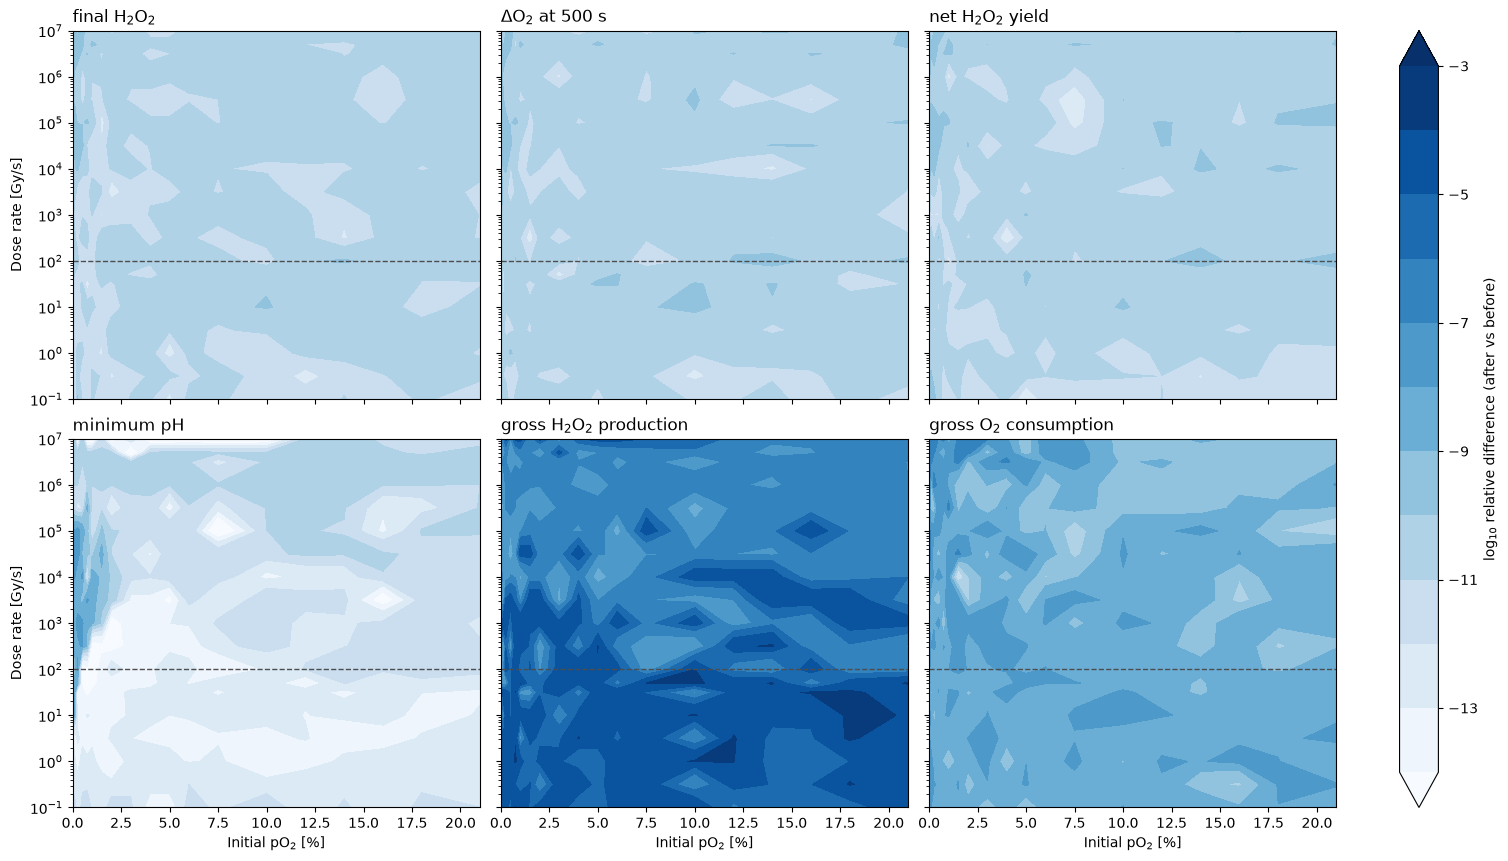

In [3]:
quantities = {
    "final H$_2$O$_2$": rel_diff(after["h2o2_final"][:, :, -1], before["h2o2_final"][:, :, -1]),
    "ΔO$_2$ at 500 s": rel_diff(pr.delta_o2(after), pr.delta_o2(before)),
    "net H$_2$O$_2$ yield": rel_diff(pr.net_yield_map(after), pr.net_yield_map(before)),
    "minimum pH": rel_diff(after["ph_min"][:, :, -1], before["ph_min"][:, :, -1]),
    "gross H$_2$O$_2$ production": rel_diff(after["h2o2_production"], before["h2o2_production"]),
    "gross O$_2$ consumption": rel_diff(after["o2_consumption"], before["o2_consumption"]),
}
logs = {k: np.log10(np.maximum(v, 1e-16)) for k, v in quantities.items()}
levels = np.arange(-14, -2.9, 1.0)
X, Y = np.meshgrid(PO2, DR)
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), sharex=True, sharey=True, constrained_layout=True)
for ax, (name, z) in zip(axes.flat, logs.items()):
    cf = ax.contourf(X, Y, z, levels=levels, cmap="Blues", extend="both")
    ax.set_title(name, loc="left")
    ax.set_yscale("log")
    ax.axhline(UHDR_LIMIT, ls="--", color="0.3", lw=1)
for ax in axes[1]:
    ax.set_xlabel("Initial pO$_2$ [%]")
for ax in axes[:, 0]:
    ax.set_ylabel("Dose rate [Gy/s]")
fig.colorbar(cf, ax=axes, label="log$_{10}$ relative difference (after vs before)")
plt.show()

## Time evolution

30 Gy, 1 % pO$_2$, four dose rates of table 5. Top row: the two codes (solid: after, dots: before; the curves overlap). Bottom row: relative difference over time.

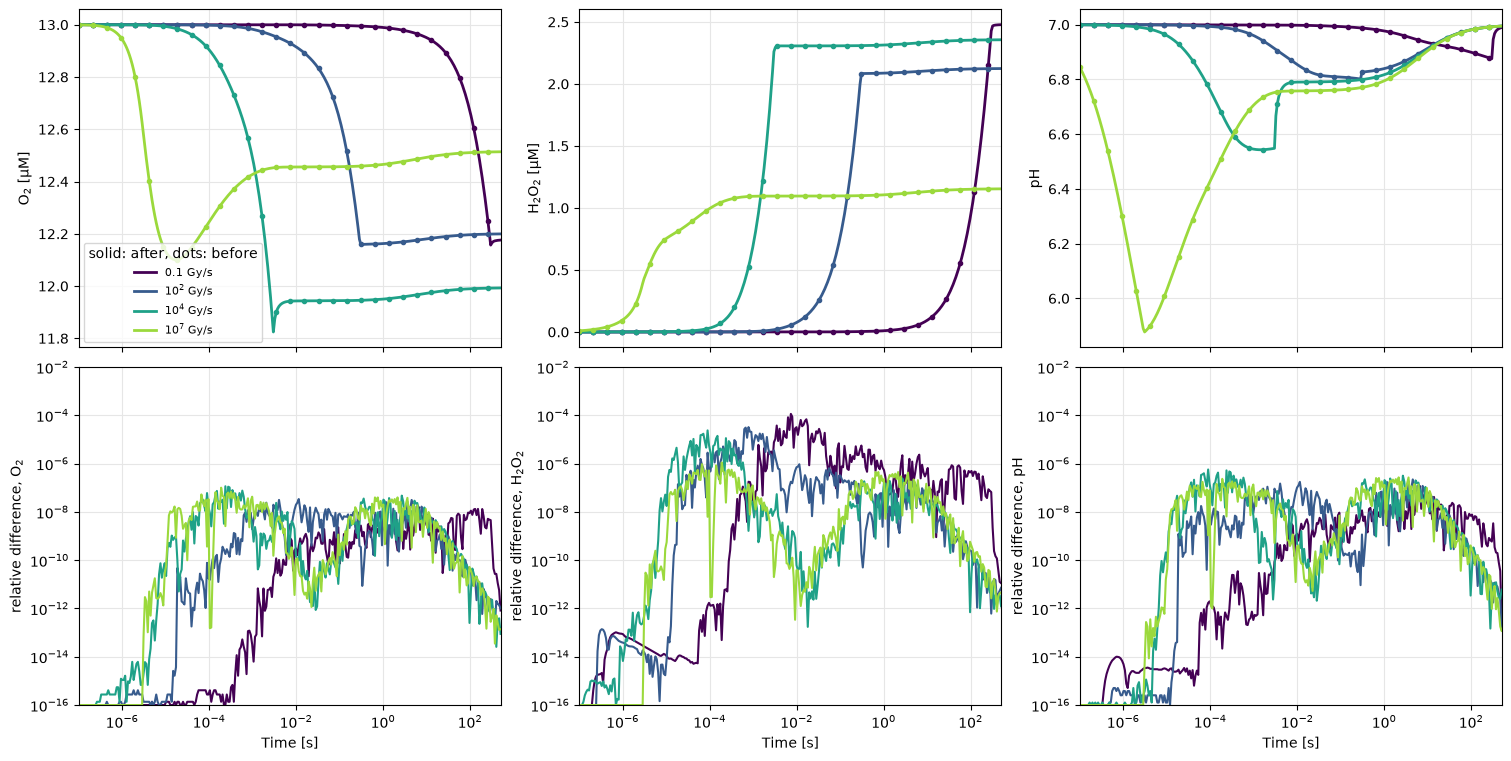

In [4]:
TS_SHOW = (0.1, 1e2, 1e4, 1e7)
SERIES = (("ts_o2", "O$_2$ [µM]"), ("ts_h2o2", "H$_2$O$_2$ [µM]"), ("ts_ph", "pH"))
shades = plt.get_cmap("viridis")(np.linspace(0.0, 0.85, len(TS_SHOW)))
b = pr.index_of(after["ts_po2"], 1.0)
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True, constrained_layout=True)
for c, (key, ylabel) in enumerate(SERIES):
    for dr, shade in zip(TS_SHOW, shades):
        a = pr.index_of(TS_DR, dr)
        axes[0, c].plot(TIME, after[key][a, b], color=shade, lw=2, label=f"{fmt_dr(dr)} Gy/s")
        axes[0, c].plot(TIME[::10], before[key][a, b][::10], "o", color=shade, ms=3)
        axes[1, c].plot(TIME, np.maximum(rel_diff(after[key][a, b], before[key][a, b]), 1e-16),
                        color=shade, lw=1.5)
    axes[0, c].set_ylabel(ylabel)
    axes[1, c].set_ylabel(f"relative difference, {ylabel.split(' [')[0]}")
    axes[1, c].set_yscale("log")
    axes[1, c].set_ylim(1e-16, 1e-2)
    axes[1, c].set_xlabel("Time [s]")
    for ax in axes[:, c]:
        ax.set_xscale("log")
        ax.set_xlim(TIME[0], TIME[-1])
        ax.grid(color="0.9")
axes[0, 0].legend(title="solid: after, dots: before", fontsize=8)
plt.show()

## Values quoted in the paper

Same rows as the reproduction notebook, with both codes.

In [5]:
q_before, q_after = pr.quoted_values(before, UHDR_LIMIT), pr.quoted_values(after, UHDR_LIMIT)
table = pd.DataFrame(
    [(q, cond, ref, b[3], a[3], src) for (q, cond, ref, _, src), b, a in zip(q_after, q_before, q_after)],
    columns=["quantity", "condition", "paper", "before (2261b92)", "after", "source"],
)
table["after vs before"] = table["after"] / table["before (2261b92)"] - 1.0
table["after vs paper"] = table["after"] / table["paper"] - 1.0
table.style.format(
    {"paper": "{:.3g}", "before (2261b92)": "{:.4g}", "after": "{:.4g}",
     "after vs before": "{:+.1e}", "after vs paper": "{:+.0%}"}
).hide(axis="index")

quantity,condition,paper,before (2261b92),after,source,after vs before,after vs paper
final H2O2 [µM],"1 % pO2, 1e2 Gy/s",2.2,2.124,2.124,"§3.3, fig. 7B",-7.2e-12,-3%
final H2O2 [µM],"1 % pO2, 1e4 Gy/s",2.45,2.356,2.356,"§3.3, fig. 7B",-1.2e-12,-4%
final H2O2 [µM],"1 % pO2, 1e7 Gy/s",1.25,1.154,1.154,"§3.3, fig. 7B",-4.6e-12,-8%
final H2O2 [µM],"5 % pO2, 1e2 Gy/s",1.75,1.693,1.693,"§3.3 (1.7-1.8), fig. 7D",+2.4e-11,-3%
final H2O2 [µM],"5 % pO2, 1e7 Gy/s",1.1,1.046,1.046,"§3.3, fig. 7D",-3.7e-12,-5%
"final H2O2 [µM], CDR min",1 % pO2,2,1.942,1.942,§3.3 (2.0-2.7),+1.5e-11,-3%
"final H2O2 [µM], CDR max",1 % pO2,2.7,2.477,2.477,§3.3 (2.0-2.7),-1.1e-11,-8%
"final H2O2 [µM], CDR min",5 % pO2,1.7,1.727,1.727,§3.3 (1.7-3.3),-6.2e-11,+2%
"final H2O2 [µM], CDR max",5 % pO2,3.3,3.063,3.063,§3.3 (1.7-3.3),+5.4e-13,-7%
"ΔO2 at 500 s [µM], CDR min",1 and 5 % pO2,0.8,0.5704,0.5704,§3.2.1 (0.8-1.2),-7.5e-11,-29%


## Reading the comparison

- **The refactoring leaves the paper's results unchanged.** The final concentrations (H$_2$O$_2$, O$_2$) agree to better than 10$^{-8}$ relative over the whole grid, the minimum pH to better than 10$^{-7}$, and the quoted values to about 10$^{-11}$ (gross O$_2$ 10$^{-7}$, net H$_2$O$_2$ production 4×10$^{-5}$). That is solver tolerance, not a change in the chemistry.
- **The largest differences, about 10$^{-4}$, are in the gross H$_2$O$_2$ production integral and in the small early H$_2$O$_2$ values of the time series** (0.1 Gy/s, while H$_2$O$_2$ is still near zero, 10$^{-6}$ µM absolute). The integrals are rebuilt from the stored solver points, and the two codes store different points: the analytic Jacobian changes the LSODA steps, the chunks follow the beam exactly, and the initial burst is now counted in the production integrals. The minimum pH differs most near 0 % pO$_2$ at UHDR, where the radical chemistry is stiffest (still ≤ 10$^{-7}$).
- **The gaps to the paper (−3 to −8 % on the final H$_2$O$_2$, −29 % on ΔO$_2$, see `tonneau_2025_pmb.ipynb`) are the same before and after**: the refactoring does not cause them. They come from the inputs: the quoted values were produced at LET 0.56 keV/µm with the config `CONFIG_PAPER_01.toml`, and the `"original"` scenario of `tonneau_2025_pmb.ipynb` reproduces them to about 1 %.
- The "before" file is a fixed record: rerun `record_pre_refactor.py` only if the numpy or scipy versions of the golden data change.